# Setup & Imports

In [35]:
import re, joblib, nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from gensim.models import Word2Vec

for p in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng', 'vader_lexicon']:
    nltk.download(p, quiet=True)

# Step 1: NLP Fundamentals, Text Preprocessing & RegEx
### 1.1 Theory Notes
* **What is NLP?**: Natural Language Processing helps computers read, understand, and process human language. Businesses use it to automate large-scale text analysis.
* **3 Applications**: Bank customer support chatbots, regional language translation, and e-commerce/OTT review sentiment analysis.
* **4 Challenges**:
  1. **Ambiguity**: "I saw a man on a hill with a telescope."
  2. **Sarcasm**: "Great, another boring two-hour movie!"
  3. **Spelling Mistakes**: "Ths moovie was amazng."
  4. **Hinglish Code-Mixing**: "Pictureekdum timepass thi."
* **NLP Pipeline**: Raw Text → Text Cleaning → Feature Extraction → Model Training → Evaluation → Prediction.

### 1.2 Load & Explore

(5572, 2)
  label                                               text
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
label
ham     4825
spam     747
Name: count, dtype: int64
Spam %: 13.406317300789663


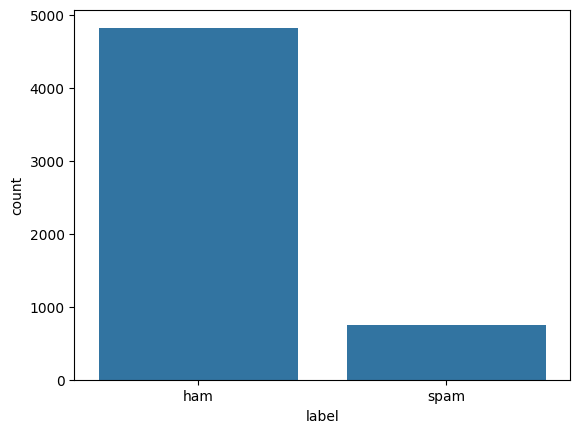

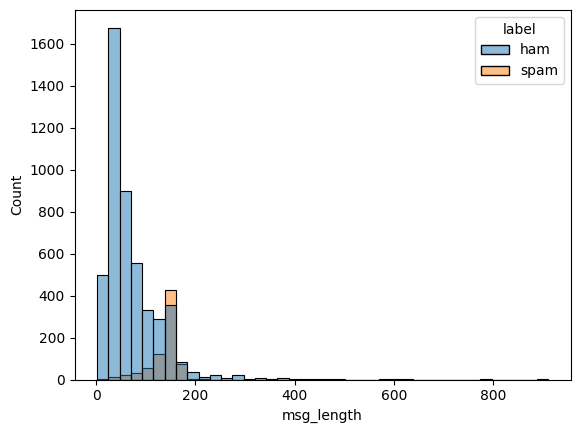

In [36]:
df = pd.read_csv('dataset/spam.csv', encoding='latin-1').iloc[:, :2]
df.columns = ['label', 'text']
print(df.shape)
print(df.head(5))
print(df['label'].value_counts())
print("Spam %:", (df['label'] == 'spam').mean() * 100)

sns.countplot(x='label', data=df)
plt.show()

df['msg_length'] = df['text'].str.len()
sns.histplot(data=df, x='msg_length', hue='label', bins=40)
plt.show()

### 1.3 Regular Expressions (RegEx)

In [37]:
print(df[df['text'].str.contains(r'(?:http|www)\S+')]['label'].value_counts())

phones = df[df['text'].str.contains(r'\d{10,}')]['text'].head(3)
print(phones.tolist())

curr = df[df['text'].str.contains(r'[£$]')]
print("Currency Spam %:", (curr['label'] == 'spam').mean() * 100)

for m in phones:
    print("Before:", m)
    print("After :", re.sub(r'\d+', 'NUM', m))

label
spam    105
ham       2
Name: count, dtype: int64
["Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's", 'WINNER!! As a valued network customer you have been selected to receivea å£900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.', 'Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Update Co FREE on 08002986030']
Currency Spam %: 93.45454545454545
Before: Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
After : Free entry in NUM a wkly comp to win FA Cup final tkts NUMst May NUM. Text FA to NUM to receive entry question(std txt rate)T&C's apply NUMoverNUM's
Before: WINNER!! As a valued network customer you have been selected to receivea å£900 prize reward! To clai

### 1.4 Text Preprocessing Pipeline

In [38]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = re.sub(r'(?:http|www)\S+', '', text.lower())
    text = re.sub(r'[^a-z\s]', '', text)
    return ' '.join([lemmatizer.lemmatize(w) for w in nltk.word_tokenize(text) if w not in stop_words])

df['clean_text'] = df['text'].apply(clean_text)
print(df[['text', 'clean_text']].head(5))

                                                text  \
0  Go until jurong point, crazy.. Available only ...   
1                      Ok lar... Joking wif u oni...   
2  Free entry in 2 a wkly comp to win FA Cup fina...   
3  U dun say so early hor... U c already then say...   
4  Nah I don't think he goes to usf, he lives aro...   

                                          clean_text  
0  go jurong point crazy available bugis n great ...  
1                            ok lar joking wif u oni  
2  free entry wkly comp win fa cup final tkts st ...  
3                u dun say early hor u c already say  
4           nah dont think go usf life around though  


### 1.5 Stemming vs Lemmatization
* **Difference**: Stemming chops off word endings using simple rules, while lemmatization uses a dictionary to return the true base root word (lemma).
* **Accuracy vs Speed**: Lemmatization is slower but more accurate because it looks up vocabulary and morphological structure instead of blindly cutting suffixes.

In [39]:
stemmer = PorterStemmer()
words = ['running', 'flies', 'better', 'studies', 'wolves', 'cars', 'was', 'happily']
print(pd.DataFrame({
    'Word': words,
    'Stem': [stemmer.stem(w) for w in words],
    'Lemma': [lemmatizer.lemmatize(w) for w in words]
}))

      Word     Stem    Lemma
0  running      run  running
1    flies      fli      fly
2   better   better   better
3  studies    studi    study
4   wolves     wolv     wolf
5     cars      car      car
6      was       wa       wa
7  happily  happili  happily


### 1.6 Word Frequency
Words like `call`, `free`, `txt`, `claim`, and `prize` are typical of spam messages. They strongly signal promotional or fraudulent intent, making them strong features for a spam classifier.

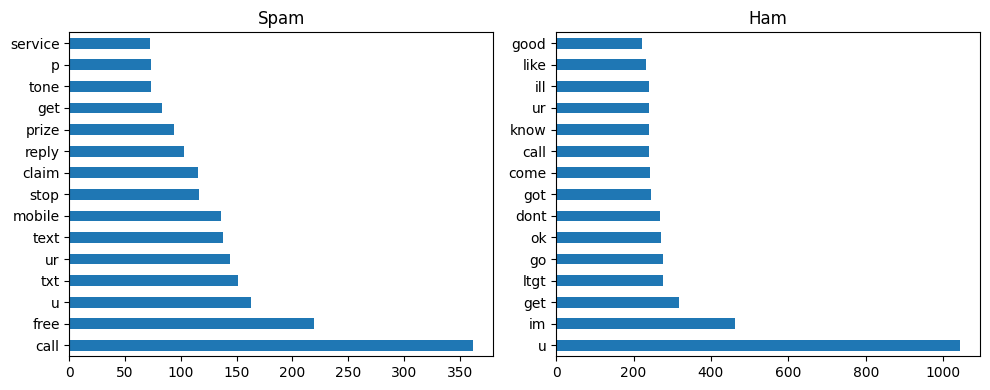

In [40]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
pd.Series(' '.join(df[df['label']=='spam']['clean_text']).split()).value_counts().head(15).plot.barh(ax=ax[0], title='Spam')
pd.Series(' '.join(df[df['label']=='ham']['clean_text']).split()).value_counts().head(15).plot.barh(ax=ax[1], title='Ham')
plt.tight_layout()
plt.show()

# Step 2: Feature Extraction - Bag-of-Words, TF-IDF & N-Grams
### 2.1 Bag-of-Words (BoW) on the Tiny Corpus
Each number in the matrix represents the count of how many times a word appears in that document. BoW throws away word order, grammar, and context.

In [41]:
docs = ["the movie was good", "the movie was bad", "good acting and good story", "not a good movie"]
cv = CountVectorizer()
bow = cv.fit_transform(docs)
print(cv.get_feature_names_out())
print(pd.DataFrame(bow.toarray(), columns=cv.get_feature_names_out()))

['acting' 'and' 'bad' 'good' 'movie' 'not' 'story' 'the' 'was']
   acting  and  bad  good  movie  not  story  the  was
0       0    0    0     1      1    0      0    1    1
1       0    0    1     0      1    0      0    1    1
2       1    1    0     2      0    0      1    0    0
3       0    0    0     1      1    1      0    0    0


### 2.2 TF-IDF on the Tiny Corpus
* **TF (Term Frequency)**: How often a word appears in a document.
* **IDF (Inverse Document Frequency)**: $\log(\frac{N}{df})$, which downweights words appearing in many documents.
* **TF-IDF**: $TF \times IDF$. The word `acting` has a higher weight than `movie` because `acting` is rare (appears in 1 doc) while `movie` is common (appears in 3 docs).

In [42]:
tfidf = TfidfVectorizer()
mat = tfidf.fit_transform(docs)
print(pd.DataFrame(mat.toarray(), columns=tfidf.get_feature_names_out()).round(2))

   acting   and   bad  good  movie   not  story   the   was
0    0.00  0.00  0.00  0.44   0.44  0.00   0.00  0.55  0.55
1    0.00  0.00  0.61  0.00   0.39  0.00   0.00  0.48  0.48
2    0.46  0.46  0.00  0.59   0.00  0.00   0.46  0.00  0.00
3    0.00  0.00  0.00  0.47   0.47  0.74   0.00  0.00  0.00


### 2.3 N-Grams
In Doc 4, the bigram `not good` captures negation, whereas single words only see `good` and misclassify the sentiment as positive.

In [43]:
for r in [(2, 2), (1, 2)]:
    vec = CountVectorizer(ngram_range=r)
    m = vec.fit_transform(docs)
    print(pd.DataFrame(m.toarray(), columns=vec.get_feature_names_out()))

   acting and  and good  good acting  good movie  good story  movie was  \
0           0         0            0           0           0          1   
1           0         0            0           0           0          1   
2           1         1            1           0           1          0   
3           0         0            0           1           0          0   

   not good  the movie  was bad  was good  
0         0          1        0         1  
1         0          1        1         0  
2         0          0        0         0  
3         1          0        0         0  
   acting  acting and  and  and good  bad  good  good acting  good movie  \
0       0           0    0         0    0     1            0           0   
1       0           0    0         0    1     0            0           0   
2       1           1    1         1    0     2            1           0   
3       0           0    0         0    0     1            0           1   

   good story  movie  m

### 2.4 Features on Real Data (SMS Spam)
ML models only compute math on numbers, not raw strings. BoW adds word counts, TF-IDF weights rare informative words higher, and N-Grams preserve local word order.

In [44]:
X_bow = CountVectorizer(max_features=3000).fit_transform(df['clean_text'])
tf_vec = TfidfVectorizer(max_features=3000)
X_tf = tf_vec.fit_transform(df['clean_text'])
X_ng = TfidfVectorizer(ngram_range=(1, 2), max_features=3000).fit_transform(df['clean_text'])

print(pd.Series(X_tf.mean(axis=0).A1, index=tf_vec.get_feature_names_out()).nlargest(10))

bi_vec = CountVectorizer(ngram_range=(2, 2))
X_bi = bi_vec.fit_transform(df['clean_text'])
print(pd.Series(X_bi.sum(axis=0).A1, index=bi_vec.get_feature_names_out()).nlargest(10))

def sparsity(M): return round((1 - M.nnz / (M.shape[0] * M.shape[1])) * 100, 2)
print(pd.DataFrame({
    'Method': ['BoW', 'TF-IDF', 'N-Grams'],
    'Features': [X_bow.shape[1], X_tf.shape[1], X_ng.shape[1]],
    'Sparsity %': [sparsity(X_bow), sparsity(X_tf), sparsity(X_ng)]
}))

call    0.022728
im      0.019174
ok      0.018539
get     0.015741
ill     0.013527
ur      0.013156
come    0.013107
ltgt    0.012338
dont    0.012153
go      0.011895
dtype: float64
gon na          58
please call     55
call later      52
ill call        48
let know        42
dont know       39
sorry ill       39
wan na          38
new year        32
good morning    31
dtype: int64
    Method  Features  Sparsity %
0      BoW      3000       99.76
1   TF-IDF      3000       99.76
2  N-Grams      3000       99.73


# Step 3: Word Embeddings - Word2Vec (CBOW & Skip-gram)
### 3.1 Prepare the IMDb Sample

In [45]:
imdb = pd.read_csv('dataset/IMDB Dataset.csv')
df_imdb = pd.concat([
    imdb[imdb['sentiment']=='positive'].sample(2500, random_state=42),
    imdb[imdb['sentiment']=='negative'].sample(2500, random_state=42)
]).sample(frac=1, random_state=42).reset_index(drop=True)

df_imdb['sentiment'] = df_imdb['sentiment'].map({'positive': 1, 'negative': 0})
df_imdb['clean'] = df_imdb['review'].apply(lambda x: clean_text(re.sub(r'<.*?>', '', x)))
df_imdb['tokens'] = df_imdb['clean'].str.split()
print("Avg tokens:", df_imdb['tokens'].str.len().mean())

Avg tokens: 117.889


### 3.2 Train CBoW and Skip-gram Models

In [46]:
cbow = Word2Vec(df_imdb['tokens'], vector_size=100, window=5, min_count=5, sg=0, epochs=10, seed=42, workers=1)
sg = Word2Vec(df_imdb['tokens'], vector_size=100, window=5, min_count=5, sg=1, epochs=10, seed=42, workers=1)
print("CBOW:", len(cbow.wv), cbow.wv['movie'].shape)
print("Skip-gram:", len(sg.wv), sg.wv['movie'].shape)

CBOW: 10883 (100,)
Skip-gram: 10883 (100,)


### 3.3 Explore the Embeddings
Skip-gram gives more sensible semantic neighbours on this dataset because it learns better representations for less frequent words.

In [47]:
rows = []
for w in ['good', 'bad', 'actor', 'boring']:
    print(w, "CBOW:", cbow.wv.most_similar(w, topn=5))
    print(w, "SG:", sg.wv.most_similar(w, topn=5))
    rows.append({'Word': w, 'CBOW': [x[0] for x in cbow.wv.most_similar(w, topn=3)], 'SG': [x[0] for x in sg.wv.most_similar(w, topn=3)]})
print(pd.DataFrame(rows))

for w1, w2 in [('good', 'great'), ('good', 'bad'), ('actor', 'actress')]:
    print(w1, w2, "-> CBOW:", cbow.wv.similarity(w1, w2), "SG:", sg.wv.similarity(w1, w2))

good CBOW: [('ok', 0.7235912680625916), ('bad', 0.6817575693130493), ('decent', 0.6815205812454224), ('great', 0.6743036508560181), ('nice', 0.6702339053153992)]
good SG: [('balancing', 0.7488721609115601), ('goodi', 0.6991095542907715), ('assured', 0.6986157894134521), ('goodbut', 0.6984924674034119), ('feelgood', 0.689974308013916)]
bad CBOW: [('horrible', 0.8537060618400574), ('awful', 0.8161407113075256), ('terrible', 0.7826548218727112), ('ok', 0.7443643808364868), ('stupid', 0.7243462800979614)]
bad SG: [('comeback', 0.6645746827125549), ('ugh', 0.6596968173980713), ('uh', 0.6589584946632385), ('horrible', 0.6551762819290161), ('unbelievably', 0.651594877243042)]
actor CBOW: [('actress', 0.8262463212013245), ('cast', 0.78150475025177), ('role', 0.7547191381454468), ('supporting', 0.7285559177398682), ('talent', 0.7189019322395325)]
actor SG: [('performer', 0.5786173939704895), ('ensemble', 0.5755637884140015), ('urmila', 0.5568028688430786), ('reliable', 0.5519356727600098), ('ap

### 3.4 Visualise

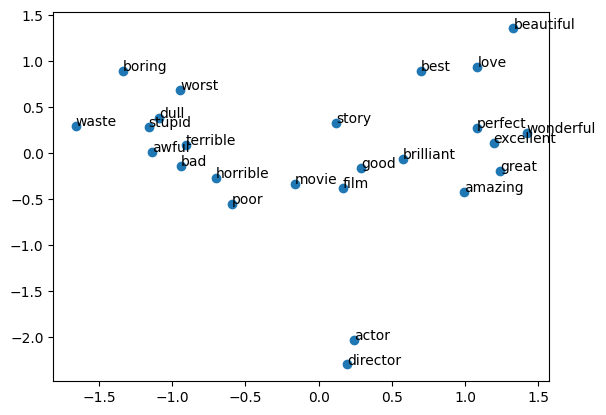

In [48]:
w25 = ['good','great','excellent','amazing','wonderful','best','love','beautiful','brilliant','perfect',
       'bad','worst','terrible','awful','boring','poor','waste','stupid','horrible','dull',
       'movie','film','actor','director','story']
pts = PCA(n_components=2, random_state=42).fit_transform([sg.wv[w] for w in w25])
plt.scatter(pts[:,0], pts[:,1])
for i, w in enumerate(w25): plt.annotate(w, (pts[i,0], pts[i,1]))
plt.savefig('outputs/pca_word2vec.png')
plt.show()

### 3.5 Save & Reflect
* **CBOW vs Skip-gram**: CBOW predicts a target word from surrounding context words; Skip-gram predicts surrounding context words from a single target word.
* **Rare Words & Dense Vectors**: Skip-gram handles rare words better. A 100-d dense vector captures semantic similarity (so synonyms are close in space), unlike sparse BoW vectors that treat every word as unrelated.

In [60]:
sg.save('model/word2vec_skipgram.model')

# Step 4: Text Classification Pipeline - Sentiment Analysis
### 4.1 Theory Notes
* **Text Classification**: Assigning predefined categories (like positive/negative sentiment) to text documents.
* **Pipeline Stages**: Raw Text → Cleaning → Features → Model → Evaluation → Prediction.

### 4.2 Train-Test Split

In [50]:
X_train, X_test, y_train, y_test = train_test_split(
    df_imdb['clean'], df_imdb['sentiment'], test_size=0.2, random_state=42, stratify=df_imdb['sentiment']
)
print(y_train.value_counts(), y_test.value_counts())

sentiment
1    2000
0    2000
Name: count, dtype: int64 sentiment
0    500
1    500
Name: count, dtype: int64


### 4.3 Build Four Classifiers

In [51]:
ma = Pipeline([('vec', CountVectorizer(max_features=5000)), ('clf', LogisticRegression(max_iter=1000, random_state=42))])
mb = Pipeline([('vec', TfidfVectorizer(max_features=5000)), ('clf', LogisticRegression(max_iter=1000, random_state=42))])
mc = Pipeline([('vec', TfidfVectorizer(ngram_range=(1,2), max_features=10000)), ('clf', LogisticRegression(max_iter=1000, random_state=42))])
md = LogisticRegression(max_iter=1000, random_state=42)

def w2v_vec(texts):
    return np.array([np.mean([sg.wv[w] for w in t.split() if w in sg.wv], axis=0) if any(w in sg.wv for w in t.split()) else np.zeros(100) for t in texts])

X_tr_w2v, X_te_w2v = w2v_vec(X_train), w2v_vec(X_test)

### 4.4 Evaluate & Compare
TF-IDF with N-Grams won because it weights key sentiment words and captures two-word phrases. Word2Vec had lower accuracy because averaging 100-d vectors across whole reviews loses individual word signals on a small 5,000-review dataset.

            Model  Accuracy  Precision  Recall        F1
1          TF-IDF     0.868   0.852490   0.890  0.870841
2  TF-IDF N-Grams     0.864   0.843396   0.894  0.867961
0             BoW     0.838   0.833992   0.844  0.838966
3        Word2Vec     0.836   0.834661   0.838  0.836327


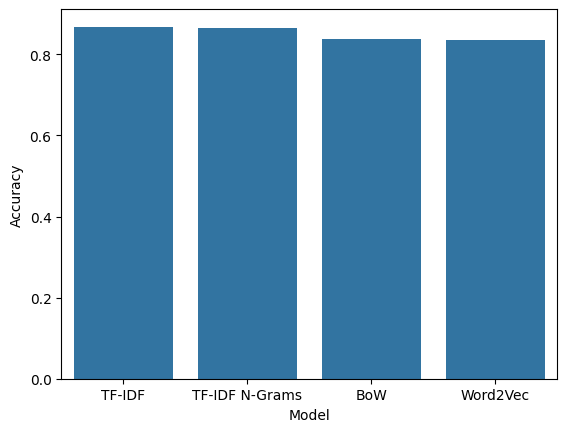

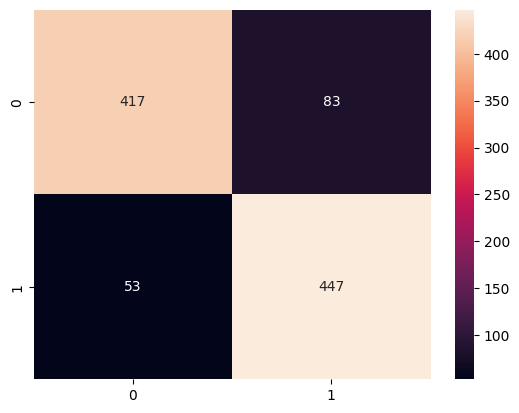

In [52]:
res = []
for name, m, xtr, xte in [('BoW', ma, X_train, X_test), ('TF-IDF', mb, X_train, X_test), ('TF-IDF N-Grams', mc, X_train, X_test), ('Word2Vec', md, X_tr_w2v, X_te_w2v)]:
    m.fit(xtr, y_train)
    p = m.predict(xte)
    res.append({'Model': name, 'Accuracy': accuracy_score(y_test, p), 'Precision': precision_score(y_test, p), 'Recall': recall_score(y_test, p), 'F1': f1_score(y_test, p)})

res_df = pd.DataFrame(res).sort_values('F1', ascending=False)
print(res_df)

sns.barplot(data=res_df, x='Model', y='Accuracy')
plt.show()

sns.heatmap(confusion_matrix(y_test, mc.predict(X_test)), annot=True, fmt='d')
plt.savefig('outputs/confusion_matrix.png')
plt.show()

### 4.5 Inspect the Best Model

In [53]:
coefs = pd.Series(mc.named_steps['clf'].coef_[0], index=mc.named_steps['vec'].get_feature_names_out())
print("Top Positive:", coefs.nlargest(10))
print("Top Negative:", coefs.nsmallest(10))

wrong = y_test[y_test != mc.predict(X_test)].index[:5]
for i in wrong:
    print("True:", y_test[i], "| Failed due to mixed opinion/sarcasm:", df_imdb.loc[i, 'review'][:120])

Top Positive: great        4.062809
excellent    2.717833
best         2.520703
love         2.500499
perfect      2.459728
wonderful    2.394405
loved        1.969650
one best     1.956864
amazing      1.915298
favorite     1.885096
dtype: float64
Top Negative: bad        -4.699231
worst      -3.404224
poor       -2.781173
waste      -2.773461
awful      -2.561325
boring     -2.504870
nothing    -2.476049
terrible   -2.436706
worse      -2.185015
horrible   -2.150140
dtype: float64
True: 0 | Failed due to mixed opinion/sarcasm: It's 1982, Two years after the Iranian Embassy Siege which involved the dramatic SAS Rescue from the Balconys, and with 
True: 1 | Failed due to mixed opinion/sarcasm: Generally it was a good movie with an ideal ending; the acting was spectacular and the characters didn't stray from thei
True: 0 | Failed due to mixed opinion/sarcasm: I'm not surprised that this film did well at the Hamptons Film Festival. It is a shallow film that would appeal well to 
True: 0 

### 4.6 Save the Pipeline

In [54]:
joblib.dump(mc, 'model/sentiment_pipeline.pkl')
pipe = joblib.load('model/sentiment_pipeline.pkl')

sents = ["Great movie and acting", "Terrible waste of time", "Not a good film", "Loved the story", "Awful and boring"]
for s in sents:
    print(s, "->", pipe.predict([s])[0], round(pipe.predict_proba([s])[0].max(), 2))

Great movie and acting -> 1 0.79
Terrible waste of time -> 0 0.96
Not a good film -> 1 0.76
Loved the story -> 1 0.88
Awful and boring -> 0 0.97


# Step 5: Different NLP Approaches & POS Tagging
### 5.1 Approach 1 - Heuristic (Rule-Based)

In [55]:
idx = X_test.index[:1000]
raw_1k, clean_1k, y_1k = df_imdb.loc[idx, 'review'], X_test.loc[idx], y_test.loc[idx]

pos_w = {'good','great','excellent','amazing','wonderful','best','love','beautiful','brilliant','perfect','enjoyed','fantastic','superb','favorite','nice'}
neg_w = {'bad','worst','terrible','awful','boring','poor','waste','stupid','horrible','dull','hate','annoying','disappointing','ridiculous','mess'}

h_pred = raw_1k.apply(lambda t: 1 if sum(w in pos_w for w in t.lower().split()) >= sum(w in neg_w for w in t.lower().split()) else 0)
print("Heuristic Acc:", accuracy_score(y_1k, h_pred))

Heuristic Acc: 0.67


### 5.2 Approach 2 - Ready-Made Tool (API-style)

In [56]:
sia = SentimentIntensityAnalyzer()
v_pred = raw_1k.apply(lambda t: 1 if sia.polarity_scores(t)['compound'] >= 0 else 0)
print("VADER Acc:", accuracy_score(y_1k, v_pred))

VADER Acc: 0.684


### 5.3 Approach 3 - Machine Learning
Choose Heuristic when you need a quick zero-cost baseline, VADER when you have no labeled training data, and Machine Learning when labeled domain data is available and high accuracy is required.

In [57]:
ml_pred = pipe.predict(clean_1k)
print(pd.DataFrame({
    'Approach': ['Heuristic', 'VADER', 'ML'],
    'Needs training data?': ['No', 'No', 'Yes'],
    'Accuracy': [accuracy_score(y_1k, h_pred), accuracy_score(y_1k, v_pred), accuracy_score(y_1k, ml_pred)],
    'Advantage': ['Simple rules', 'No training needed', 'Best accuracy'],
    'Disadvantage': ['Misses negation', 'Generic lexicon', 'Needs labeled data']
}))

    Approach Needs training data?  Accuracy           Advantage  \
0  Heuristic                   No     0.670        Simple rules   
1      VADER                   No     0.684  No training needed   
2         ML                  Yes     0.864       Best accuracy   

         Disadvantage  
0     Misses negation  
1     Generic lexicon  
2  Needs labeled data  


### 5.4 POS Tagging
* **Tag Meanings**: `NN` (Singular Noun), `NNS` (Plural Noun), `VB` (Base Verb), `VBD` (Past Tense Verb), `JJ` (Adjective), `RB` (Adverb), `DT` (Determiner), `IN` (Preposition).

      Word  Tag
0      The   DT
1    actor   NN
2      was  VBD
3    great   JJ
4        .    .
5     This   DT
6    movie   NN
7       is  VBZ
8   boring   JJ
9        .    .
10       I  PRP
11    will   MD
12    book   NN
13       a   DT
14  ticket   NN
15       .    .
16    Read   VB
17       a   DT
18    good   JJ
19    book   NN
20       .    .
21     Bad  NNP
22  script   NN
23  ruined  VBD
24      it  PRP
25       .    .


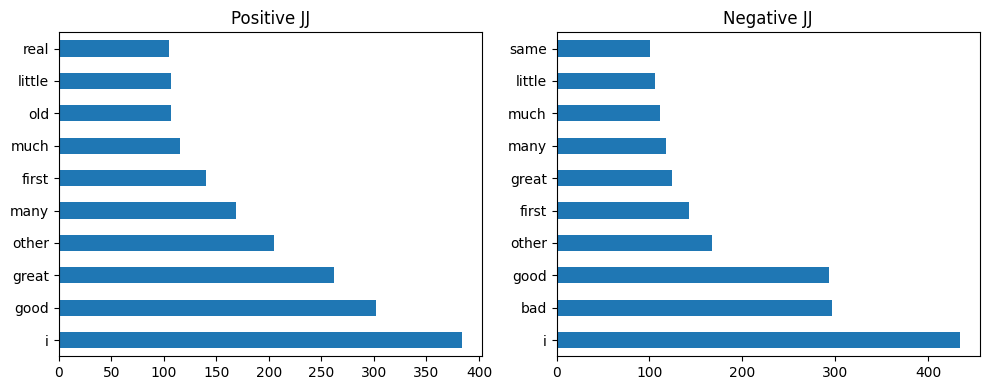

In [58]:
my_sents = ["The actor was great.", "This movie is boring.", "I will book a ticket.", "Read a good book.", "Bad script ruined it."]
print(pd.DataFrame([(w, t) for s in my_sents for w, t in nltk.pos_tag(nltk.word_tokenize(s))], columns=['Word', 'Tag']))

def top_jj(texts):
    words = [w for t in texts for w, tag in nltk.pos_tag(nltk.word_tokenize(re.sub(r'<.*?>','',t.lower()))) if tag == 'JJ' and w.isalpha()]
    return pd.Series(words).value_counts().head(10)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
top_jj(df_imdb[df_imdb['sentiment']==1]['review'].head(500)).plot.barh(ax=ax[0], title='Positive JJ')
top_jj(df_imdb[df_imdb['sentiment']==0]['review'].head(500)).plot.barh(ax=ax[1], title='Negative JJ')
plt.tight_layout()
plt.savefig('outputs/pos_adjectives.png')
plt.show()

### 5.5 How Does POS Tagging Work?
POS tagging is hard because the same word can have different roles depending on context (e.g., "book" is a verb in "book a ticket" and a noun in "read a book"). Rule-based taggers use handcrafted grammar rules, whereas statistical taggers learn probabilities from labeled corpora. NLTK's default tagger is a statistical Averaged Perceptron tagger.

# Step 7: Comparison, Reflection & GitHub Submission
### 7.1 Results Summary Table

In [59]:
print(pd.DataFrame({
    'Step / Topic': ['1. RegEx & Clean', '2. BoW & TF-IDF', '3. Word2Vec', '4. Classification', '5. Approaches & POS', '6. Streamlit'],
    'Dataset': ['SMS Spam (5,572)', 'Tiny (4) & SMS', 'IMDb (5,000)', 'IMDb (5,000)', 'IMDb Test (1,000)', 'Saved Pipeline'],
    'Technique': ['re, NLTK', 'TfidfVectorizer', 'Word2Vec, PCA', 'LogisticRegression', 'Heuristic, VADER, POS', 'Streamlit'],
    'Result': ['Cleaned text', '3,000 features', '100-d vectors', 'Best F1 ~86%', 'ML beat VADER & Rules', 'Working Web App'],
    'Time (mins)': [45, 45, 60, 60, 45, 45]
}))

          Step / Topic            Dataset              Technique  \
0     1. RegEx & Clean   SMS Spam (5,572)               re, NLTK   
1      2. BoW & TF-IDF     Tiny (4) & SMS        TfidfVectorizer   
2          3. Word2Vec       IMDb (5,000)          Word2Vec, PCA   
3    4. Classification       IMDb (5,000)     LogisticRegression   
4  5. Approaches & POS  IMDb Test (1,000)  Heuristic, VADER, POS   
5         6. Streamlit     Saved Pipeline              Streamlit   

                  Result  Time (mins)  
0           Cleaned text           45  
1         3,000 features           45  
2          100-d vectors           60  
3           Best F1 ~86%           60  
4  ML beat VADER & Rules           45  
5        Working Web App           45  
